# scikit-tda tutorial: from point clouds to graph persistence

An executable companion to the [scikit-tda tutorial](https://docs.scikit-tda.org/en/latest/notebooks/scikit-tda%20Tutorial.html). Work through the cells in order using the **TDA (conda)** kernel. This notebook follows the guide's three main parts: Ripser's persistence API, diagram analysis and classification, and graph persistence.

The original graph example depends on separate atmospheric chemistry CSV files. Part 3 uses a generated bipartite graph so every cell runs without downloads. The classification example also uses smaller samples to keep the exercise practical on a laptop. Results will differ from the guide's figures.

**Reading a diagram:** each point is a feature at `(birth, death)`; farther above the diagonal means longer persistence. $H_0$ counts connected components and $H_1$ counts loops. These descriptions depend on the filtration and do not, by themselves, establish statistical significance.

## Before the code: what question does TDA answer?

**Topological data analysis (TDA)** studies how data are connected across scales. Imagine sampling dots around a circle. Very close up, they are isolated dots. As the distance used to connect them grows, they join into a loop. At a larger distance, enough connections and filled triangles appear to fill that loop. Persistent homology records when these features appear and disappear.

The word **shape** can describe relationships in a table with hundreds of columns, not just a visible drawing. You first decide what an observation is and what “close” means. Those choices determine what topology you measure.

### The objects you will pass between packages

```text
observations → distances → growing complexes → persistence diagrams
                                                 ├─ compare two diagrams
                                                 └─ image/landscape → numerical features → model
```

| Object | Meaning | Example in this notebook |
|---|---|---|
| Point cloud | One row per point; one column per coordinate or feature | `noisy`, shape `(100, 2)` |
| Distance matrix | Entry `[i, j]` says how far points i and j are apart | `distance_matrix`, shape `(100, 100)` |
| Filtration | A nested sequence of shapes as a threshold increases | Built internally by Ripser |
| Persistence diagram | Rows of birth and death values for one homology dimension | `noisy_dgms[1]`, shape `(number_of_H1_features, 2)` |
| Feature vector | A fixed number of measurements suitable for a model | One flattened persistence image per cloud |

### Which package does which job?

| Package | Its job here | When you would reach for it |
|---|---|---|
| **TaDAsets** (`tadasets`) | Generate circles with known structure | Learn the methods or test an idea on controlled data |
| **Ripser** (`ripser`, `Rips`) | Compute persistence from points or distances | Ask which components, loops, or higher dimensional holes persist |
| **Persim** | Plot, compare, and summarize diagrams | Interpret persistence or turn it into model inputs |
| **NumPy** | Store arrays and generate random samples | Prepare data and manipulate outputs |
| **SciPy** | Compute pairwise and graph distances | Define the relationships Ripser will analyze |
| **Matplotlib** | Draw the figures | Inspect inputs and results |
| **scikit-learn** | Split data, scale features, and fit a classifier | Predict labels from topological summaries |

Scikit-tda is an ecosystem of tools; you usually import the specific package you need. This notebook focuses on Ripser and Persim. See the [README](README.md) for applications and other tools mentioned in the guide.

### Three ideas to recognize in every plot

- **H0:** connected components. Two separated groups give two components at a suitable threshold.
- **H1:** independent loops. A ring of points can produce a loop before triangles fill its interior.
- **H2:** enclosed voids, such as the inside of a sampled spherical surface. A filled triangle itself is not an H2 feature.

A **simplex** is a building block: a vertex, an edge, a filled triangle, a filled tetrahedron, and so on. A **simplicial complex** combines these blocks with all their faces. A Vietoris–Rips complex includes a block whenever all pairs of its vertices are within the threshold. Homology describes holes in the resulting complex, not just which blocks were added.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import shortest_path
from ripser import ripser, Rips
from persim import (plot_diagrams, PersistenceImager, PersLandscapeApprox,
                    bottleneck, bottleneck_matching)
from persim.landscapes import plot_landscape_simple
import tadasets

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

def diagram_sizes(diagrams):
    return ", ".join(f"H{i}: {len(d)}" for i, d in enumerate(diagrams))

## 1. Persistence API

### 1.1 Point clouds, the function API, and the `Rips` class

The guide starts with clean and noisy samples from a circle. We fix the random seed so the comparison is reproducible. `ripser` accepts point coordinates directly; `Rips` wraps the same computation in a class interface.

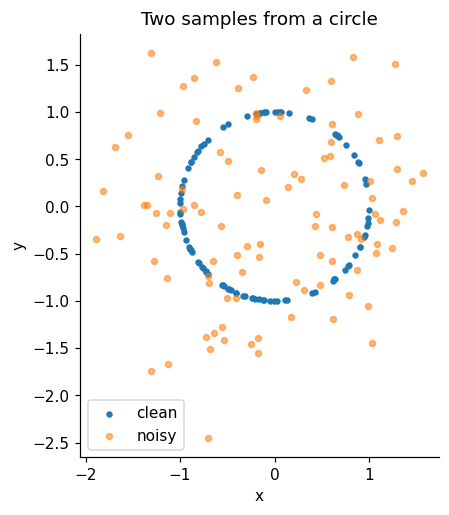

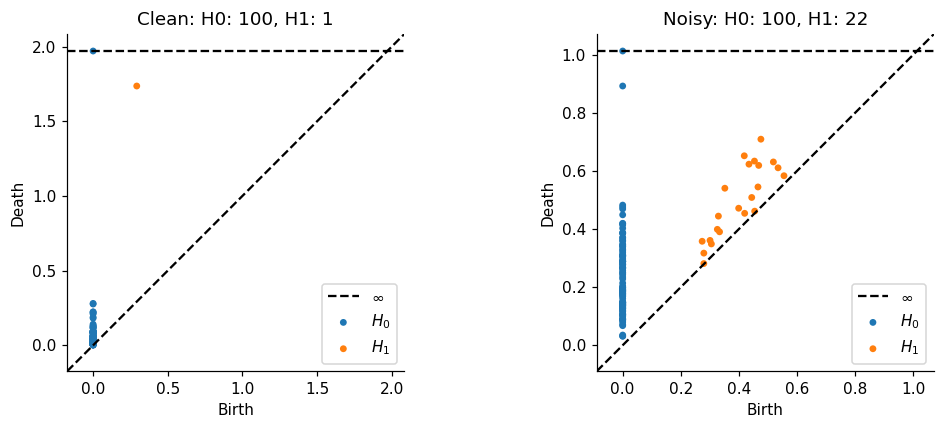

In [15]:
clean = tadasets.dsphere(d=1, n=100, noise=0.0, seed=565656)
noisy = tadasets.dsphere(d=1, n=100, noise=0.50, seed=565657)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*clean.T, s=10, label="clean")
ax.scatter(*noisy.T, s=15, alpha=0.55, label="noisy")
ax.set(xlabel="x", ylabel="y", title="Two samples from a circle", aspect="equal")
ax.legend() #dots 
plt.show()

clean_dgms = ripser(clean)["dgms"]
rips = Rips(maxdim=1, verbose=False)
noisy_dgms = rips.fit_transform(noisy)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_diagrams(clean_dgms, ax=axes[0], title=f"Clean: {diagram_sizes(clean_dgms)}")
plot_diagrams(noisy_dgms, ax=axes[1], title=f"Noisy: {diagram_sizes(noisy_dgms)}")
plt.tight_layout()
plt.show()

#### Read the circle results

`ripser(clean)` returns a dictionary. Its `"dgms"` value is a list: index 0 contains H0, index 1 contains H1. The `Rips` class offers an object interface to the same computation; it is not a supervised prediction model.

For a row `[0.3, 1.6]`, a feature is present from threshold 0.3 until 1.6, so its **persistence** is 1.3. The coordinates measure scale, not the location of the feature in the original scatter plot. A diagram point does not directly tell you which original points form the loop.

Look for one H1 point well above the diagonal in the clean circle. Shorter features in the noisy sample may come from sampling or noise. Persistence alone does not establish their scientific importance. One H0 class has infinite death because the final connected component remains.

### 1.2 Distance matrices and Ripser options

Passing pairwise distances is useful when the input is an abstract metric space or a graph. For a Euclidean cloud, it should produce the same diagram as passing the coordinates. `maxdim` controls the highest homology dimension, while `thresh` stops adding simplices above a given **pairwise distance**. We use a modest `thresh` and compare the number of detected classes.

Coordinate and distance-matrix diagrams agree.
Thresholded: H0: 100, H1: 19
Through H2: H0: 100, H1: 22, H2: 0


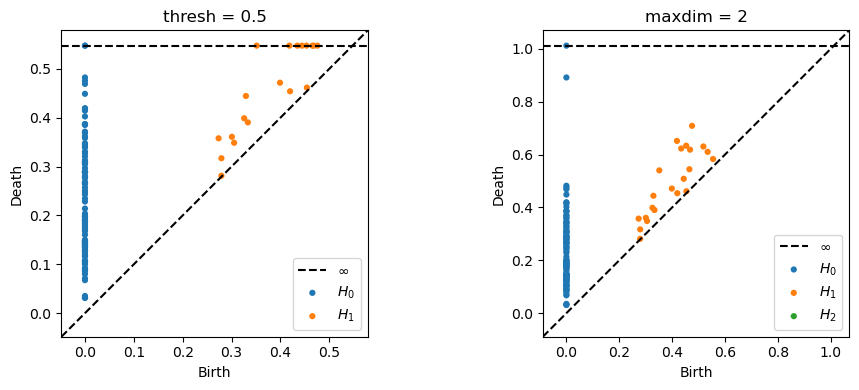

In [16]:
distance_matrix = squareform(pdist(noisy))
from_matrix = ripser(distance_matrix, distance_matrix=True)["dgms"]
for direct, matrix in zip(noisy_dgms, from_matrix):
    np.testing.assert_allclose(direct, matrix, atol=1e-6)
print("Coordinate and distance-matrix diagrams agree.")

threshold = 0.5
limited = ripser(noisy, maxdim=1, thresh=threshold)["dgms"]
full_h2 = ripser(noisy, maxdim=2)["dgms"]
print("Thresholded:", diagram_sizes(limited))
print("Through H2:", diagram_sizes(full_h2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_diagrams(limited, ax=axes[0], title=f"thresh = {threshold}")
plot_diagrams(full_h2, ax=axes[1], title="maxdim = 2")
plt.tight_layout()
plt.show()

#### What changing the parameters means

- `maxdim=1` requests H0 and H1. It does not mean Ripser uses only edges: filled triangles are needed to determine when loops die.
- `thresh=0.5` stops the filtration at pairwise distance 0.5. An infinite death in this truncated calculation can mean “still alive when we stopped.”
- `coeff=2` is the default field used in the algebra. Other prime values can reveal different behavior in some spaces; start with 2 for these examples. The parameter is `coeff`, including in the class API.
- `n_perm` can use a smaller representative sample for speed, at the cost of approximation. Increasing point count or homology dimension can make computation much more expensive.

These controls are documented in the [Ripser API](https://ripser.scikit-tda.org/en/latest/reference/stubs/ripser.ripser.html).

**Distance choices matter.** If one table column is measured in thousands and another in tenths, raw Euclidean distance can be dominated by the first. Choose units, scaling, and a metric that match your question. Multiplying all distances by 3 also multiplies diagram birth and death values by 3.

**Check your understanding:** if a loop has birth 0.3 and death 1.6, would you see its death with `thresh=0.5`? No; the run stops before that event.

### 1.3 Plotting, lifetimes, and persistence images

Comparing only $H_1$ removes the many short lived $H_0$ points. Persim can also plot persistence (`death − birth`) and convert a diagram into a fixed size image. Essential classes with infinite death are excluded from the image.

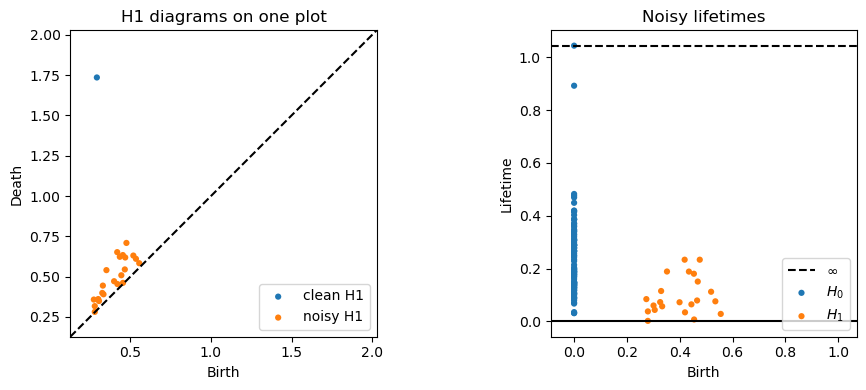

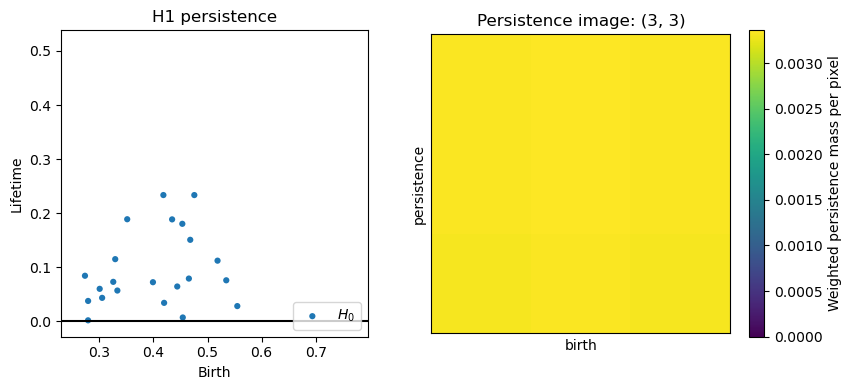

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_diagrams([clean_dgms[1], noisy_dgms[1]],
              labels=["clean H1", "noisy H1"], ax=axes[0],
              title="H1 diagrams on one plot")
plot_diagrams(noisy_dgms, lifetime=True, ax=axes[1],
              title="Noisy lifetimes")
plt.tight_layout()
plt.show()

imager = PersistenceImager(pixel_size=0.1)
imager.fit([noisy_dgms[1]])
image = imager.transform(noisy_dgms[1])
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_diagrams([noisy_dgms[1]], lifetime=True, ax=axes[0], title="H1 persistence")
imager.plot_image(image, ax=axes[1])
axes[1].set_title(f"Persistence image: {image.shape}")
axes[1].images[-1].set_clim(vmin=0, vmax=float(image.max()))
fig.colorbar(axes[1].images[-1], ax=axes[1],
             label="Weighted persistence mass per pixel")
plt.tight_layout()
plt.show()

#### Why turn a diagram into an image?

Different clouds produce different numbers of persistence points. A classifier generally needs the same number of features for every example. A persistence image converts the diagram to a common grid in **birth–persistence coordinates**, spreads weighted contributions around its points, and records grid values. Flattening that grid yields a vector.

This image summarizes a diagram; its pixels are not positions in the original point cloud. The grid bounds, pixel size, and smoothing affect which details survive. Smaller pixels produce more features, which can demand more training data. Reuse the same fitted imager when comparing examples. See [Persim's persistence image explanation](https://persim.scikit-tda.org/en/latest/notebooks/Persistence%20images.html).

**Read the colorbar:** a pixel contains the sum of weighted, smoothed contributions integrated over that pixel. With the default settings here, longer persistence intervals receive more weight. A bright region can therefore reflect longer lived features, several overlapping contributions, or both. Values are not probabilities or literal counts of holes. The side-by-side classification images share one color scale; separate automatic scales could otherwise make different values look equally bright. Pixel size, weighting, and smoothing change the values, so compare images made with the same settings.

### 1.4 A persistence landscape

A landscape is another vector based summary of a diagram. We use $H_1$ so all death times are finite in this example.

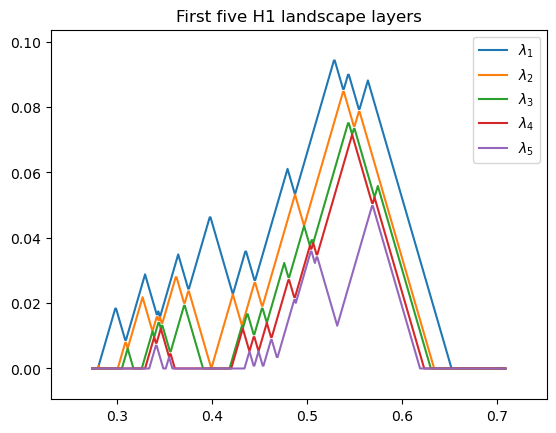

In [18]:
landscape = PersLandscapeApprox(dgms=noisy_dgms, hom_deg=1)
plot_landscape_simple(landscape, depth_range=range(1, 6))
plt.title("First five H1 landscape layers")
plt.show()

#### What is a landscape?

For a finite birth–death pair `(b, d)`, imagine a triangular tent that starts at b, peaks halfway to d, and returns to zero at d. At each scale, the tallest tent gives the first landscape layer, the second tallest gives the next, and so on.

Landscapes turn diagrams into functions that can be sampled on a shared grid, averaged, or compared with function norms. `PersLandscapeApprox` samples an approximation. Long intervals produce tall tents. Layers rank tent heights at each scale; a layer need not track one fixed topological feature across the entire plot. The next sections use persistence images as the model representation.

## 2. Analysis of persistence diagrams

### 2.1 Bottleneck distance

The bottleneck distance measures the largest matched displacement between diagrams, allowing matches to the diagonal. A small value means the diagrams are close under this matching. It is not a hypothesis test.

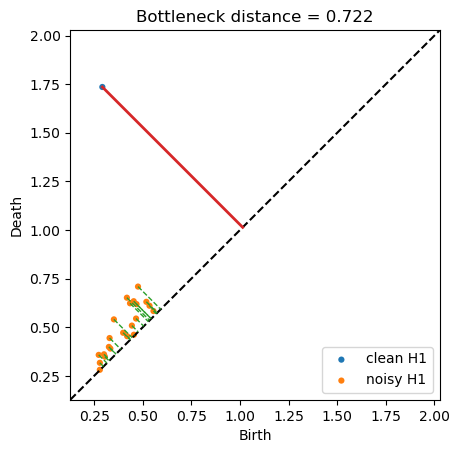

In [19]:
bottleneck_distance, matching = bottleneck(clean_dgms[1], noisy_dgms[1], matching=True)
bottleneck_matching(clean_dgms[1], noisy_dgms[1], matching,
                    labels=["clean H1", "noisy H1"])
plt.title(f"Bottleneck distance = {bottleneck_distance:.3f}")
plt.show()

#### What does the bottleneck matching measure?

Match diagram points to one another or to the diagonal. Pair cost is the larger absolute change in birth or death (the L-infinity distance). Bottleneck distance chooses a matching whose largest cost is as small as possible.

Matching to the diagonal lets a feature disappear; a short interval can do this cheaply. Compare diagrams computed with compatible distance units and filtrations. A distance between two diagrams summarizes a difference in their topology but does not tell you its cause.

### 2.2 Classifying clouds with persistence images

The guide distinguishes uniform noise from noise containing two circles. We generate a smaller balanced sample, compute one $H_1$ diagram per cloud, turn each diagram into a persistence image, and train an L1 penalized logistic regression model. The train/test split is stratified and fixed for reproducibility. The score is illustrative; a single small split is not a reliable estimate of generalization.

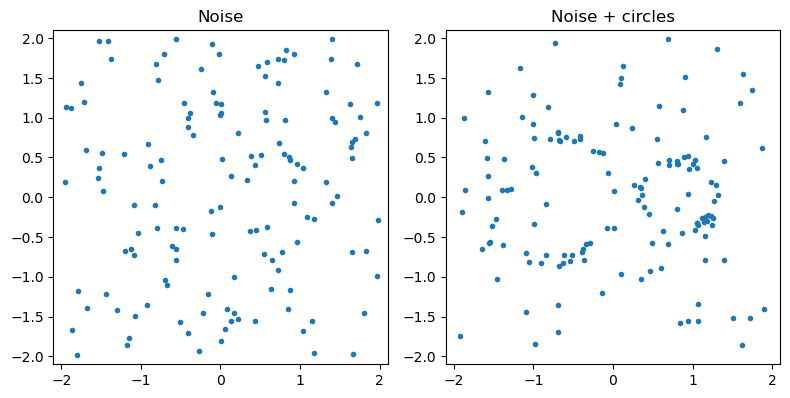

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(565656)
M, N = 24, 140  # 12 clouds per class; 140 points per cloud

def uniform_noise(n):
    return rng.uniform(-2, 2, (n, 2))

def two_circles(n):
    n1 = n // 2
    t1 = rng.uniform(0, 2 * np.pi, n1)
    t2 = rng.uniform(0, 2 * np.pi, n - n1)
    outer = np.column_stack((np.cos(t1), np.sin(t1))) * 0.8 + [-0.8, 0]
    inner = np.column_stack((np.cos(t2), np.sin(t2))) * 0.45 + [0.8, 0]
    return np.vstack((outer, inner)) + rng.normal(0, 0.05, (n, 2))

clouds = [uniform_noise(N) for _ in range(M // 2)]
clouds += [np.vstack((uniform_noise(N // 2), two_circles(N // 2)))
           for _ in range(M // 2)]
labels = np.r_[np.zeros(M // 2, dtype=int), np.ones(M // 2, dtype=int)]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, idx, title in zip(axes, [0, -1], ["Noise", "Noise + circles"]):
    ax.scatter(*clouds[idx].T, s=9)
    ax.set(title=title, aspect="equal", xlim=(-2.1, 2.1), ylim=(-2.1, 2.1))
plt.tight_layout()
plt.show()

#### What is one training example?

Here **one entire point cloud is one example** with one class label. Its individual points are not the examples given to logistic regression. The two classes describe how each cloud was generated: uniform noise, or noise mixed with circles.

The next cell creates one H1 diagram per cloud. We split cloud indices before fitting the image grid, so held-out clouds do not determine the learned representation. Computing each cloud's diagram independently can happen before this split.

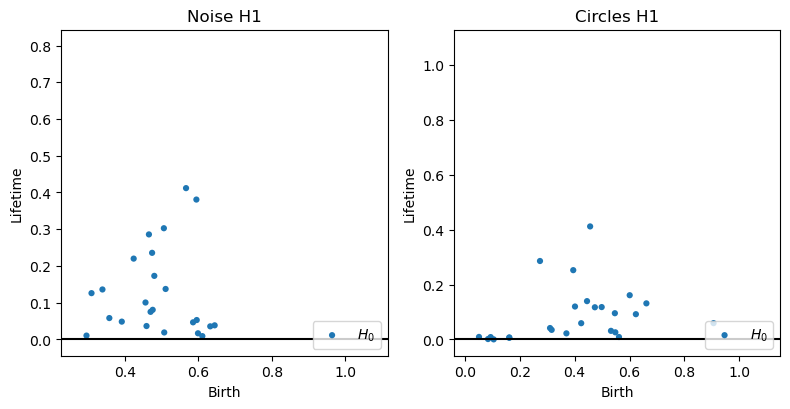

24 images, shape (5, 4), 20 features each


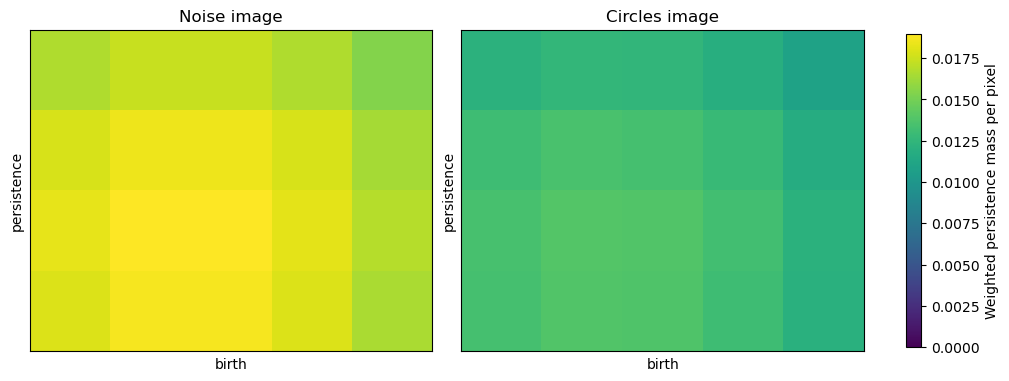

In [21]:
h1_diagrams = [ripser(cloud, maxdim=1)["dgms"][1] for cloud in clouds]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
plot_diagrams([h1_diagrams[0]], lifetime=True, ax=axes[0], title="Noise H1")
plot_diagrams([h1_diagrams[-1]], lifetime=True, ax=axes[1], title="Circles H1")
plt.tight_layout()
plt.show()

train_idx, test_idx = train_test_split(
    np.arange(len(clouds)), test_size=0.33, stratify=labels, random_state=42)
classifier_imager = PersistenceImager(pixel_size=0.2)
classifier_imager.fit([h1_diagrams[i] for i in train_idx])
images = classifier_imager.transform(h1_diagrams)
features = np.stack([img.ravel() for img in images])
print(f"{len(images)} images, shape {images[0].shape}, {features.shape[1]} features each")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
# A common scale makes the same color mean the same value in both images.
color_max = max(float(images[i].max()) for i in [0, -1])
for ax, idx, title in zip(axes, [0, -1], ["Noise image", "Circles image"]):
    classifier_imager.plot_image(images[idx], ax=ax)
    ax.images[-1].set_clim(vmin=0, vmax=color_max)
    ax.set_title(title)
fig.colorbar(axes[0].images[-1], ax=axes,
             label="Weighted persistence mass per pixel", shrink=0.8)
plt.show()

#### From images to predictions

`fit` learns settings from training data; `transform` applies those settings. For `PersistenceImager`, fitting chooses the image bounds. Its test images use the training grid, so features outside those bounds may be represented incompletely. For `StandardScaler`, fitting learns each feature's training mean and scale.

The pipeline applies scaling and logistic regression in order. Logistic regression learns a weighted combination of pixel features to predict the class. L1 regularization encourages some coefficients to become zero; `C` controls how strongly the coefficients are penalized (smaller C means stronger regularization).

Test accuracy is the fraction of held-out **clouds** labeled correctly. With only eight test clouds, one changed prediction moves accuracy by 12.5 percentage points. For a research result, use more independent samples and validation splits, compare to simpler features, and avoid choosing model settings by repeatedly inspecting test scores.

In [22]:
X_train, X_test = features[train_idx], features[test_idx]
y_train, y_test = labels[train_idx], labels[test_idx]
model = make_pipeline(StandardScaler(), LogisticRegression(
    l1_ratio=1, solver="liblinear", C=1, max_iter=2000))
model.fit(X_train, y_train)
print(f"Train accuracy: {model.score(X_train, y_train):.2f}")
print(f"Test accuracy:  {model.score(X_test, y_test):.2f} ({len(y_test)} held-out clouds)")

Train accuracy: 0.94
Test accuracy:  0.88 (8 held-out clouds)


## 3. Persistence for graphs

The guide uses a weighted bipartite species–reaction graph loaded from two CSV files. Those files were not included in the pasted guide, so this section generates a small **illustrative** bipartite graph with chemicals `C0`–`C9` and reactions `R0`–`R7`. Edge weights are positive. We compare a direct edge-weight filtration with shortest-path distances. These are different constructions, so their diagrams answer different questions.

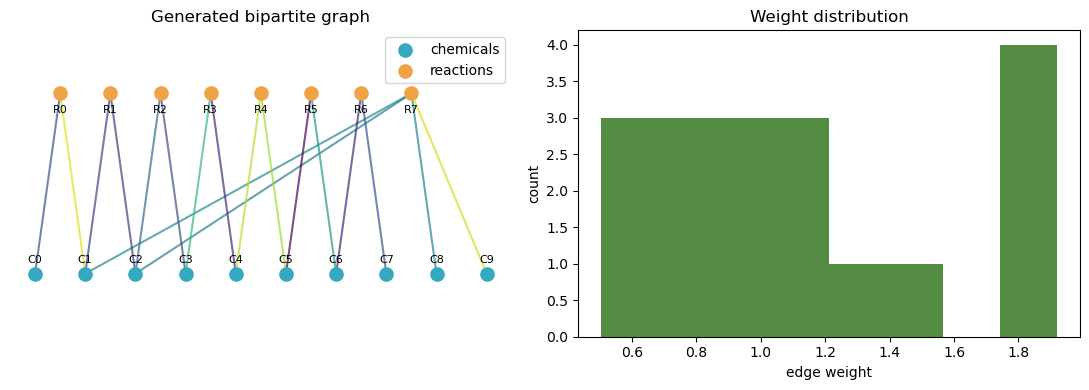

18 nodes, 18 edges; symmetric matrix: True


In [23]:
rng_graph = np.random.default_rng(12)
n_chem, n_reaction = 10, 8
names = [f"C{i}" for i in range(n_chem)] + [f"R{i}" for i in range(n_reaction)]
n_nodes = len(names)
weighted = np.full((n_nodes, n_nodes), np.inf)
np.fill_diagonal(weighted, 0)

# Each reaction connects neighboring chemicals; the last two reactions add cycles.
for r in range(n_reaction):
    chem_pairs = [(r, r + 1)] if r < 7 else [(2, 8), (1, 9)]
    for a, b in chem_pairs:
        for c in (a, b):
            w = float(rng_graph.uniform(0.5, 2.0))
            weighted[c, n_chem + r] = weighted[n_chem + r, c] = w

edges = [(i, j, weighted[i, j]) for i in range(n_chem)
         for j in range(n_chem, n_nodes) if np.isfinite(weighted[i, j])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
chem_xy = np.column_stack((np.arange(n_chem), np.zeros(n_chem)))
reaction_xy = np.column_stack((np.arange(n_reaction) + 0.5, np.ones(n_reaction)))
xy = np.vstack((chem_xy, reaction_xy))
for i, j, w in edges:
    axes[0].plot([xy[i, 0], xy[j, 0]], [xy[i, 1], xy[j, 1]],
                 color=plt.cm.viridis((w - 0.5) / 1.5), alpha=0.7)
axes[0].scatter(*chem_xy.T, s=90, color="#35a9bf", label="chemicals", zorder=3)
axes[0].scatter(*reaction_xy.T, s=90, color="#f0a344", label="reactions", zorder=3)
for i, name in enumerate(names):
    axes[0].annotate(name, xy[i], xytext=(0, 8 if i < n_chem else -14),
                     textcoords="offset points", ha="center", fontsize=8)
axes[0].set(xlim=(-0.5, 9.5), ylim=(-0.35, 1.35), title="Generated bipartite graph")
axes[0].axis("off")
axes[0].legend(loc="upper right")
axes[1].hist([w for _, _, w in edges], bins=8, color="#538b42")
axes[1].set(xlabel="edge weight", ylabel="count", title="Weight distribution")
plt.tight_layout()
plt.show()
print(f"{n_nodes} nodes, {len(edges)} edges; symmetric matrix: {np.allclose(weighted, weighted.T)}")

#### Why analyze a graph with TDA?

Graph nodes might be chemicals, people, sensors, or states. Edges express a relationship. This example is **bipartite**: edges connect chemicals to reactions, never two chemicals directly. It is synthetic and carries no actual reaction measurements.

TDA lets you study how connectivity and loops change as an edge threshold grows. You must decide what weights mean: this notebook treats small weights as short distances, so those connections enter first. A similarity score or reaction strength often needs a justified conversion before it is used as a distance.

### 3.1 Direct adjacency filtration

Missing edges have infinite dissimilarity. Ripser can build a Vietoris–Rips filtration from this symmetric matrix, but the matrix is generally **not a metric**: a direct edge may cost more than an indirect path. Its diagram describes the chosen edge-weight filtration.

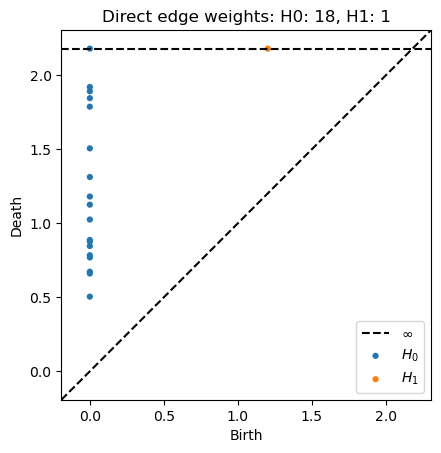

In [24]:
adjacency_dgms = ripser(weighted, distance_matrix=True, maxdim=1)["dgms"]
plot_diagrams(adjacency_dgms, title=f"Direct edge weights: {diagram_sizes(adjacency_dgms)}")
plt.show()

#### Why can a graph loop have infinite death?

In this direct edge construction, missing edges remain absent at every finite threshold. A bipartite graph has no triangles, so its cycles cannot be filled with finite-weight triangles in this filtration. That can leave H1 features with infinite death.

Those are valid outputs of the chosen filtration, rather than a plotting error. They describe the mathematical construction; they do not prove that a real chemical process contains a feedback mechanism.

### 3.2 Weighted and unweighted shortest paths

Weighted shortest paths use the sum of edge weights. Unweighted paths count edges. Both are distances on this connected undirected graph. The original tutorial calls these $L_1$ and $L_0$, respectively; here the names `weighted_paths` and `hop_paths` make the computation explicit.

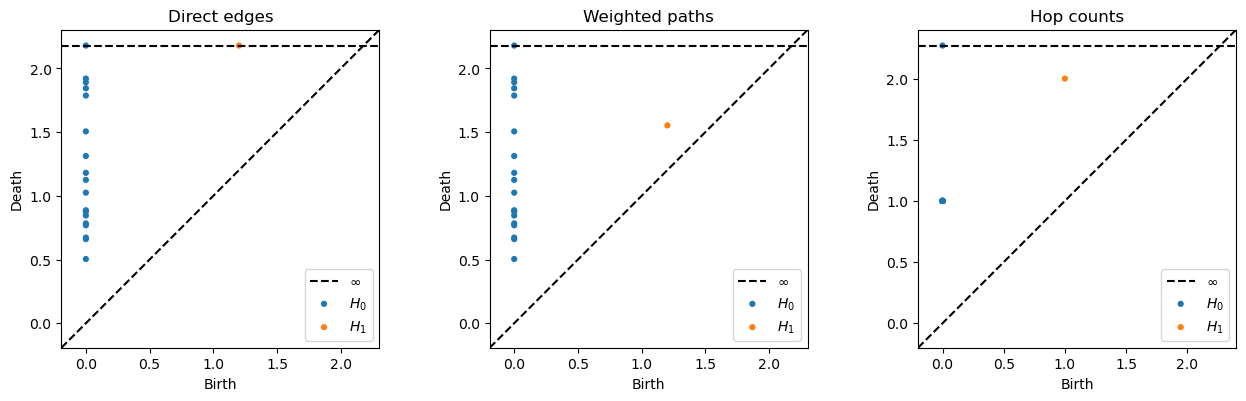

Direct: H0: 18, H1: 1
Weighted paths: H0: 18, H1: 1
Hop counts: H0: 18, H1: 1


In [25]:
weighted_paths = shortest_path(weighted, directed=False)
hop_adjacency = np.where(np.isfinite(weighted), 1.0, np.inf)
np.fill_diagonal(hop_adjacency, 0)
hop_paths = shortest_path(hop_adjacency, directed=False)
assert np.isfinite(weighted_paths).all() and np.isfinite(hop_paths).all()

weighted_dgms = ripser(weighted_paths, distance_matrix=True, maxdim=1)["dgms"]
hop_dgms = ripser(hop_paths, distance_matrix=True, maxdim=1)["dgms"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plot_diagrams(adjacency_dgms, ax=axes[0], title="Direct edges")
plot_diagrams(weighted_dgms, ax=axes[1], title="Weighted paths")
plot_diagrams(hop_dgms, ax=axes[2], title="Hop counts")
plt.tight_layout()
plt.show()
print("Direct:", diagram_sizes(adjacency_dgms))
print("Weighted paths:", diagram_sizes(weighted_dgms))
print("Hop counts:", diagram_sizes(hop_dgms))

#### The graph construction changes the question

Direct edges ask what topology is created by the recorded connections as their allowed weights increase. Shortest-path distances also assign finite separation to nodes connected indirectly. This lets new Rips edges and triangles appear between such nodes, potentially filling graph loops.

Weighted paths preserve the chosen edge lengths; hop counts use only the number of edges. For example, a route with two edges of weight 0.4 has weighted distance 0.8 and hop count 2. These diagrams use different scale units, so comparing their bottleneck distances directly would need a meaningful normalization.

## Try next

1. Raise `noise` in the point-cloud section and compare the longest $H_1$ lifetime.
2. Change the classification sample size `M` or noise level and rerun the model with a few random train/test splits.
3. Add an edge to the graph, then compare all three graph diagrams. Which construction changes most?

For package details, follow the API links in the [original tutorial](https://docs.scikit-tda.org/en/latest/notebooks/scikit-tda%20Tutorial.html).